# Hybrid Quantum-Classical Credit Card Fraud Detection

This notebook preserves the original classical ML and quantum ML experiments while adding:

1. Training-only correlation and VIF diagnostics.
2. A stratified 70% / 15% / 15% train-validation-test split.
3. Validation-based model and decision-threshold selection.
4. Quantum VQC experiments using 4, 8, 12, and 16 selected features.
5. An optional PCA dimensionality-reduction experiment.
6. A final comparison on a shared, untouched test subset for feasible quantum simulation, with a separate full-test classical report.

**Dataset expected at:** `data/creditcard.csv` relative to the notebook working directory. The target column must be named `Class` (0 = legitimate, 1 = fraud).

**Runtime note:** QML training is expensive. Start with the smaller feature counts. The final shared quantum comparison uses a controlled test subset to avoid running thousands of simulated quantum circuits; its class prevalence is not natural, so interpret precision and PR-AUC accordingly. Full-test classical results are also reported.

## Google Colab GPU support

- In Colab, choose **Runtime → Change runtime type → T4 GPU** (or another available GPU), then restart the session and run from the top.
- The notebook detects CUDA and uses it for XGBoost when the installed XGBoost build supports it, and for the added PyTorch MLP.
- Logistic Regression, Random Forest, scikit-learn MLPs, VIF/correlation analysis, and the default Qiskit Machine Learning VQC/QNN workflow are not automatically GPU-accelerated by this change. Quantum circuits generally remain simulator/primitive dependent and may run on CPU.
- A GPU runtime does not guarantee every library uses the GPU. Check the printed device and XGBoost configuration messages.


In [1]:
%pip install -q "qiskit>=1.2,<2.0" "qiskit-machine-learning>=0.8,<0.9" "qiskit-algorithms>=0.3,<0.4"

No CUDA GPU detected. GPU-enabled models will use CPU fallback where supported.
Dataset shape: (284807, 31)
PyTorch available: True; selected device: cpu
XGBoost version: 3.4.1
XGBoost CUDA requested: False
Missing values: 0
Class distribution:
Class
Legitimate    284315
Fraud            492
Name: count, dtype: int64
Fraud rate: 0.173%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


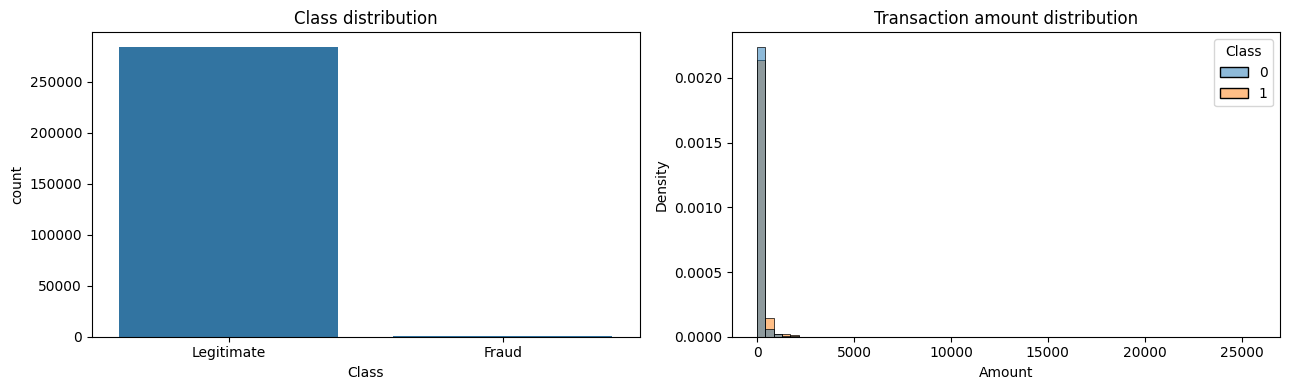

In [2]:
# 0. Imports and dataset audit
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, classification_report, ConfusionMatrixDisplay,
    confusion_matrix, PrecisionRecallDisplay, precision_recall_curve,
    roc_auc_score, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

# GPU detection for Google Colab. Enable it via Runtime > Change runtime type > GPU.
try:
    import torch
    TORCH_AVAILABLE = True
    TORCH_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    GPU_AVAILABLE = torch.cuda.is_available()
except ImportError:
    torch = None
    TORCH_AVAILABLE = False
    TORCH_DEVICE = 'cpu'
    GPU_AVAILABLE = False

if GPU_AVAILABLE:
    print(f'GPU detected: {torch.cuda.get_device_name(0)}')
else:
    print('No CUDA GPU detected. GPU-enabled models will use CPU fallback where supported.')

try:
    import xgboost as xgb
    from xgboost import XGBClassifier
    XGBOOST_VERSION = tuple(int(part) for part in xgb.__version__.split('.')[:2] if part.isdigit())
except ImportError:
    xgb = None
    XGBClassifier = None
    XGBOOST_VERSION = (0, 0)

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    from statsmodels.tools.tools import add_constant
    STATSMODELS_AVAILABLE = True
except ImportError:
    STATSMODELS_AVAILABLE = False

RANDOM_STATE = 42
DATA_PATH = Path('data') / 'creditcard.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Could not find {DATA_PATH.resolve()}. Put creditcard.csv in a data/ folder '
        'next to this notebook, or update DATA_PATH.'
    )

df = pd.read_csv(DATA_PATH)
if 'Class' not in df.columns:
    raise ValueError("Dataset must contain a target column named 'Class'.")
if df['Class'].nunique() != 2:
    raise ValueError("Expected binary target Class with values 0 and 1.")

print(f'Dataset shape: {df.shape}')
print(f'PyTorch available: {TORCH_AVAILABLE}; selected device: {TORCH_DEVICE}')
if GPU_AVAILABLE:
    print('CUDA device:', torch.cuda.get_device_name(0))
if XGBClassifier is not None:
    print('XGBoost version:', xgb.__version__)
    print('XGBoost CUDA requested:', bool(GPU_AVAILABLE))
print(f'Missing values: {df.isna().sum().sum()}')
print('Class distribution:')
print(df['Class'].value_counts().rename({0: 'Legitimate', 1: 'Fraud'}))
print(f"Fraud rate: {df['Class'].mean():.3%}")
display(df.head())
display(df.describe().T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x='Class', ax=axes[0])
axes[0].set_title('Class distribution')
axes[0].set_xticks([0, 1], ['Legitimate', 'Fraud'])
sns.histplot(data=df, x='Amount', hue='Class', bins=60, stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Transaction amount distribution')
plt.tight_layout()
plt.show()

In [3]:
# 1. Stratified 70/15/15 split and reusable preprocessing
X = df.drop(columns='Class')
y = df['Class'].astype(int)

# Reserve the final 15% test set first. Do not use it for model/threshold selection.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)
# 15% of the original data is 15/85 of the remaining 85%.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=15/85,
    stratify=y_train_val, random_state=RANDOM_STATE
)

numeric_features = X.columns.tolist()
amount_feature = ['Amount'] if 'Amount' in X.columns else []
scaled_features = [c for c in numeric_features if c not in amount_feature]

def make_preprocessor():
    """Return a fresh preprocessor; fit only on the relevant training partition."""
    transformers = []
    # Add one transformer per column in original input order. This ensures that
    # tree-model feature_importances_ still align with numeric_features.
    for column in numeric_features:
        if column == 'Amount':
            transformers.append((
                'amount',
                Pipeline([
                    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                    ('scale', StandardScaler()),
                ]),
                [column],
            ))
        else:
            transformers.append((f'scale_{column}', StandardScaler(), [column]))
    return ColumnTransformer(transformers=transformers, remainder='drop')

def build_pipeline(classifier):
    return Pipeline([
        ('preprocessor', make_preprocessor()),
        ('classifier', classifier),
    ])

def evaluate_probabilities(y_true, probabilities, threshold=0.5):
    probabilities = np.asarray(probabilities, dtype=float).reshape(-1)
    predictions = (probabilities >= threshold).astype(int)
    report = classification_report(y_true, predictions, output_dict=True, zero_division=0)
    return {
        'Precision': report['1']['precision'],
        'Recall': report['1']['recall'],
        'F1': report['1']['f1-score'],
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'PR-AUC': average_precision_score(y_true, probabilities),
        'Confusion Matrix': confusion_matrix(y_true, predictions),
        'probabilities': probabilities,
        'predictions': predictions,
        'threshold': float(threshold),
    }

print(f'Train: {len(X_train):,} rows | fraud: {int(y_train.sum()):,}')
print(f'Validation: {len(X_val):,} rows | fraud: {int(y_val.sum()):,}')
print(f'Test: {len(X_test):,} rows | fraud: {int(y_test.sum()):,}')
display(pd.DataFrame({
    'Train fraud rate': [y_train.mean()],
    'Validation fraud rate': [y_val.mean()],
    'Test fraud rate': [y_test.mean()],
}, index=['Fraud prevalence']).T)

Train: 199,364 rows | fraud: 344
Validation: 42,721 rows | fraud: 74
Test: 42,722 rows | fraud: 74


,Fraud prevalence
Train fraud rate,0.001725
Validation fraud rate,0.001732
Test fraud rate,0.001732


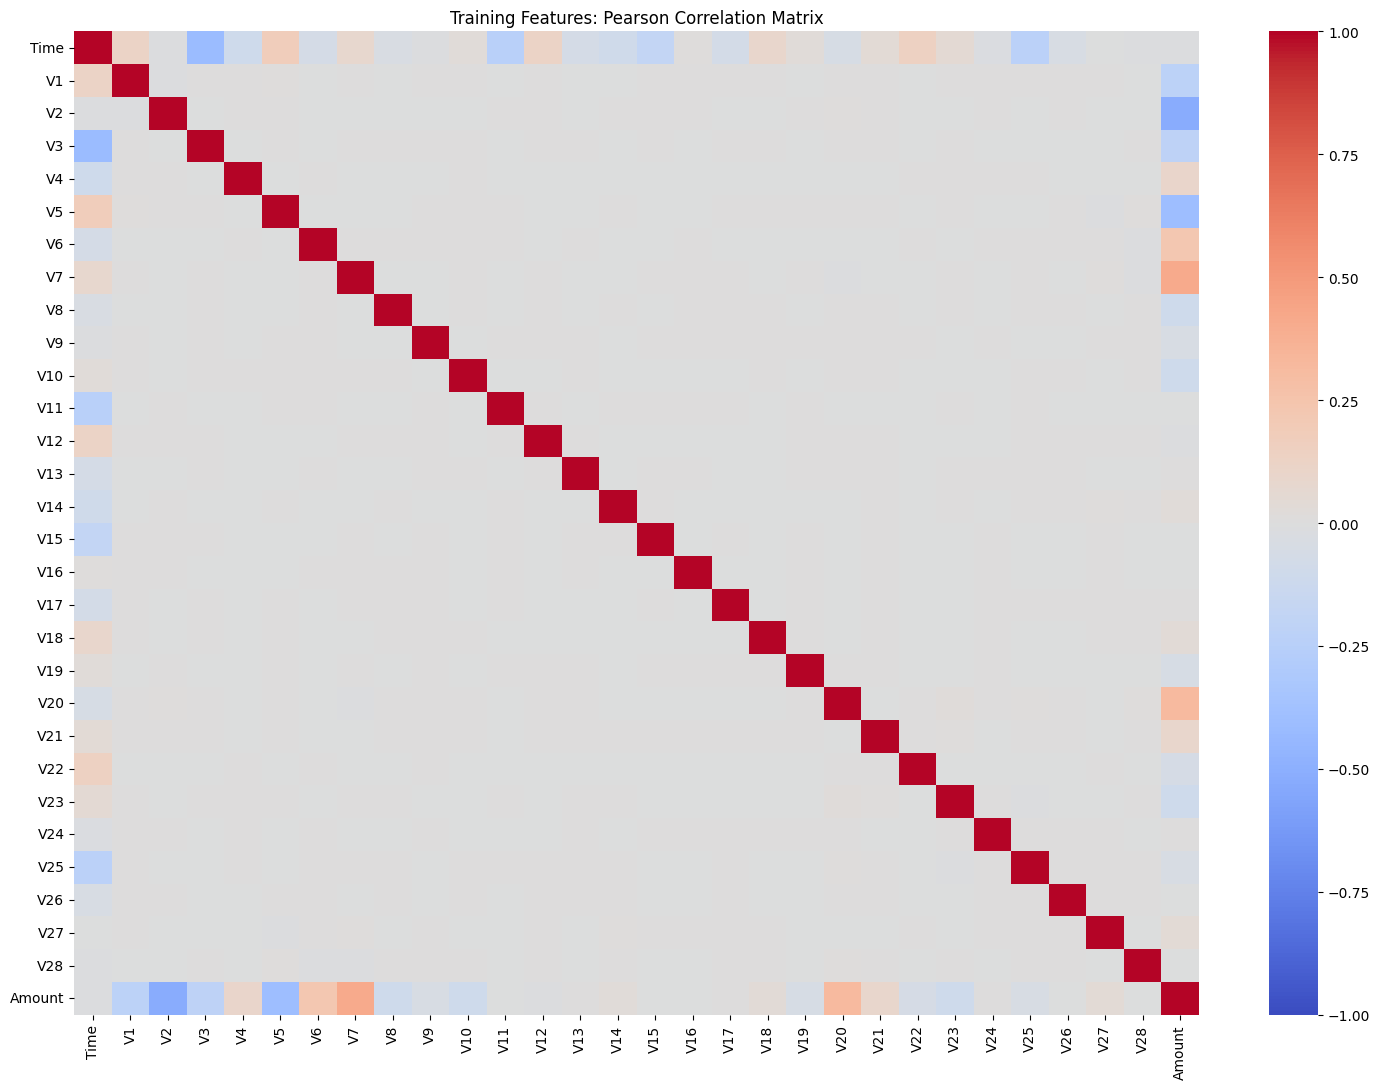

Feature pairs with |Pearson correlation| > 0.90:


,Feature 1,Feature 2,Correlation,Absolute Correlation


,Feature,VIF
29,Amount,11.701926
2,V2,4.612679
7,V7,3.138108
5,V5,3.044556
20,V20,2.562296
3,V3,1.978064
0,Time,1.876750
1,V1,1.727457
6,V6,1.649429
21,V21,1.235975


VIF > 5 is a screening guideline, not an automatic feature-removal rule.
Interpretation note: V1-V28 are PCA-transformed features and are generally designed to be uncorrelated. Do not remove features solely because of an arbitrary threshold; document what the diagnostics show.


In [4]:
# 2. Multicollinearity: Pearson correlation matrix and VIF
# Diagnostics use X_train only; Class is excluded.
corr_matrix = X_train.corr(method='pearson')
plt.figure(figsize=(15, 11))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Training Features: Pearson Correlation Matrix')
plt.tight_layout()
plt.show()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
correlated_pairs = (
    upper.stack().rename('Correlation').reset_index()
    .rename(columns={'level_0': 'Feature 1', 'level_1': 'Feature 2'})
)
correlated_pairs['Absolute Correlation'] = correlated_pairs['Correlation'].abs()
correlated_pairs = correlated_pairs[correlated_pairs['Absolute Correlation'] > 0.90].sort_values(
    'Absolute Correlation', ascending=False
)
print('Feature pairs with |Pearson correlation| > 0.90:')
display(correlated_pairs if not correlated_pairs.empty else pd.DataFrame(
    columns=['Feature 1', 'Feature 2', 'Correlation', 'Absolute Correlation']
))

if STATSMODELS_AVAILABLE:
    # A reproducible sample controls runtime; VIF does not require every training row.
    VIF_SAMPLE_SIZE = min(20_000, len(X_train))
    X_vif = X_train.sample(n=VIF_SAMPLE_SIZE, random_state=RANDOM_STATE).copy()
    # Standardize to improve numerical conditioning. VIF is invariant to scaling.
    X_vif = pd.DataFrame(StandardScaler().fit_transform(X_vif), columns=X_vif.columns)
    X_vif = add_constant(X_vif, has_constant='add')
    vif_rows = []
    for i, column in enumerate(X_vif.columns):
        if column == 'const':
            continue
        try:
            value = variance_inflation_factor(X_vif.to_numpy(), i)
        except Exception:
            value = np.nan
        vif_rows.append({'Feature': column, 'VIF': value})
    vif_table = pd.DataFrame(vif_rows).sort_values('VIF', ascending=False)
    display(vif_table)
    print('VIF > 5 is a screening guideline, not an automatic feature-removal rule.')
else:
    print('statsmodels is not installed; install it with: python3 -m pip install statsmodels')

print('Interpretation note: V1-V28 are PCA-transformed features and are generally designed to be uncorrelated. Do not remove features solely because of an arbitrary threshold; document what the diagnostics show.')

In [5]:
# 3. Train classical ML baselines; evaluate on validation data
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

models = {
    'Logistic Regression': build_pipeline(LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE
    )),
    'Random Forest': build_pipeline(RandomForestClassifier(
        n_estimators=150, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
    )),
    'Logistic Regression + SMOTE': ImbPipeline([
        ('preprocessor', make_preprocessor()),
        ('smote', SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)),
        ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
}
if XGBClassifier is not None:
    xgb_device_kwargs = {}
    if GPU_AVAILABLE:
        # XGBoost >= 2.0 uses tree_method='hist', device='cuda'.
        # Older releases used tree_method='gpu_hist'.
        if XGBOOST_VERSION >= (2, 0):
            xgb_device_kwargs = {'tree_method': 'hist', 'device': 'cuda'}
        else:
            xgb_device_kwargs = {'tree_method': 'gpu_hist'}
    else:
        xgb_device_kwargs = {'tree_method': 'hist'}

    def make_xgb_pipeline(use_gpu):
        device_kwargs = xgb_device_kwargs if use_gpu else {'tree_method': 'hist'}
        return build_pipeline(XGBClassifier(
            n_estimators=200, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=(y_train == 0).sum() / max(1, (y_train == 1).sum()),
            eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1,
            **device_kwargs,
        ))

    models['XGBoost'] = make_xgb_pipeline(use_gpu=GPU_AVAILABLE)
else:
    print('XGBoost is not installed; skipping XGBoost.')

model_results = {}
for name, model in list(models.items()):
    print(f'Fitting {name}...')
    try:
        model.fit(X_train, y_train)  # SMOTE, when used, is applied only to training rows.
    except Exception as fit_error:
        # If the local XGBoost build lacks CUDA support, retry XGBoost on CPU.
        if name == 'XGBoost' and GPU_AVAILABLE and XGBClassifier is not None:
            print(f'XGBoost GPU fit failed ({fit_error}); retrying on CPU.')
            model = make_xgb_pipeline(use_gpu=False)
            models[name] = model
            model.fit(X_train, y_train)
        else:
            raise
    val_probabilities = model.predict_proba(X_val)[:, 1]
    model_results[name] = evaluate_probabilities(y_val, val_probabilities, threshold=0.5)

validation_comparison = pd.DataFrame({
    name: {metric: result[metric] for metric in ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']}
    for name, result in model_results.items()
}).T.sort_values('PR-AUC', ascending=False)
print('Classical models on validation data at threshold 0.50:')
display(validation_comparison.style.format('{:.4f}'))

Fitting Logistic Regression...
Fitting Random Forest...
Fitting Logistic Regression + SMOTE...
Fitting XGBoost...
Classical models on validation data at threshold 0.50:


,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.6667,0.8919,0.7630,0.9894,0.8617
Random Forest,0.9355,0.7838,0.8529,0.9510,0.8586
Logistic Regression + SMOTE,0.3846,0.8784,0.5350,0.9807,0.7687
Logistic Regression,0.0669,0.9189,0.1247,0.9861,0.7597


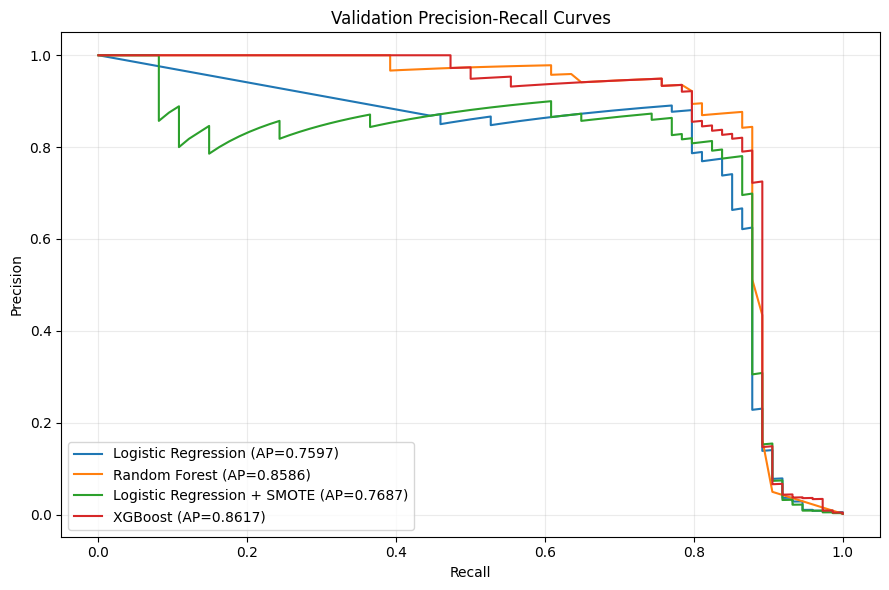

Validation-selected thresholds (maximum F1):


,Threshold,Precision,Recall,F1
Model,,,,
Logistic Regression,0.9500,0.4088,0.8784,0.5579
Random Forest,0.1500,0.8767,0.8649,0.8707
Logistic Regression + SMOTE,0.9000,0.7805,0.8649,0.8205
XGBoost,0.8500,0.8378,0.8378,0.8378


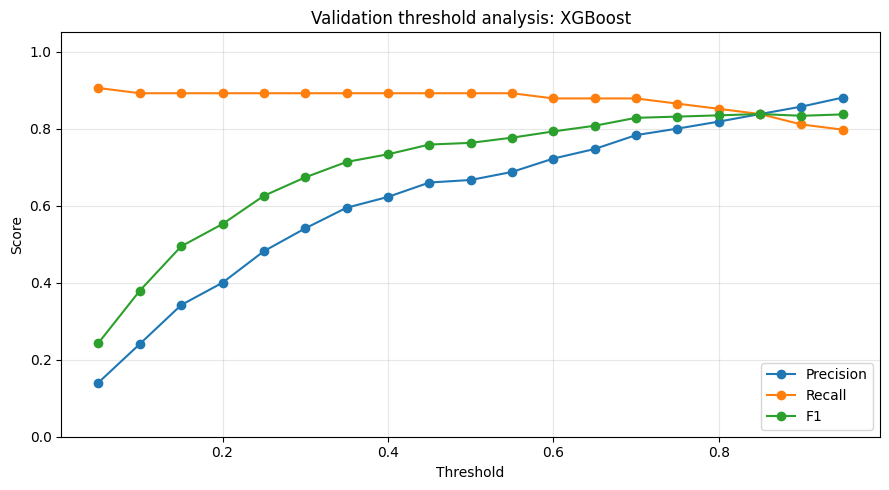

Best classical model by validation PR-AUC: XGBoost
Selected F1 threshold: 0.85


In [6]:
# 4. Validation PR curves and threshold selection (never tune on the final test set)
fig, ax = plt.subplots(figsize=(9, 6))
for name, result in model_results.items():
    precision, recall, _ = precision_recall_curve(y_val, result['probabilities'])
    ap = average_precision_score(y_val, result['probabilities'])
    ax.plot(recall, precision, label=f'{name} (AP={ap:.4f})')
ax.set_title('Validation Precision-Recall Curves')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.legend(loc='best')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

thresholds = np.linspace(0.05, 0.95, 19)  # Defined before all threshold loops.
threshold_tables = {}
thresholds_by_model = {}
for name, result in model_results.items():
    probabilities = result['probabilities']
    table = pd.DataFrame([
        {
            'Threshold': threshold,
            'Precision': precision_score(y_val, probabilities >= threshold, zero_division=0),
            'Recall': recall_score(y_val, probabilities >= threshold, zero_division=0),
            'F1': f1_score(y_val, probabilities >= threshold, zero_division=0),
        }
        for threshold in thresholds
    ])
    threshold_tables[name] = table
    thresholds_by_model[name] = float(table.loc[table['F1'].idxmax(), 'Threshold'])

print('Validation-selected thresholds (maximum F1):')
display(pd.DataFrame([
    {'Model': name, **table.loc[table['F1'].idxmax()].to_dict()}
    for name, table in threshold_tables.items()
]).set_index('Model').style.format('{:.4f}'))

best_model_name = validation_comparison.index[0]
threshold_tables[best_model_name].set_index('Threshold')[['Precision', 'Recall', 'F1']].plot(
    marker='o', figsize=(9, 5), title=f'Validation threshold analysis: {best_model_name}'
)
plt.ylabel('Score'); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f'Best classical model by validation PR-AUC: {best_model_name}')
print(f"Selected F1 threshold: {thresholds_by_model[best_model_name]:.2f}")

In [7]:
# 5. Classical neural-network baselines; fit preprocessing on training data only
from imblearn.over_sampling import RandomOverSampler
from sklearn.neural_network import MLPClassifier

NN_TRAIN_LIMIT = 20_000
if len(X_train) > NN_TRAIN_LIMIT:
    nn_X_train, _, nn_y_train, _ = train_test_split(
        X_train, y_train, train_size=NN_TRAIN_LIMIT, stratify=y_train,
        random_state=RANDOM_STATE,
    )
else:
    nn_X_train, nn_y_train = X_train.copy(), y_train.copy()

nn_preprocessor = make_preprocessor()
X_nn_train = nn_preprocessor.fit_transform(nn_X_train, nn_y_train)
X_nn_val = nn_preprocessor.transform(X_val)
X_nn_train, nn_y_train_resampled = RandomOverSampler(random_state=RANDOM_STATE).fit_resample(
    X_nn_train, nn_y_train
)

neural_models = {
    'Neural Network (1 hidden layer, scikit-learn/CPU)': MLPClassifier(
        hidden_layer_sizes=(32,), activation='relu', solver='adam', alpha=1e-4,
        batch_size=256, learning_rate_init=1e-3, max_iter=40,
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=6,
        random_state=RANDOM_STATE,
    ),
    'Neural Network (2 hidden layers, scikit-learn/CPU)': MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=1e-4,
        batch_size=256, learning_rate_init=1e-3, max_iter=50,
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=6,
        random_state=RANDOM_STATE,
    ),
}

# A PyTorch MLP runs on Colab's CUDA GPU when one is enabled. It follows the same
# fit/predict_proba interface as scikit-learn so it works with the existing evaluation code.
if TORCH_AVAILABLE:
    class TorchMLPClassifier:
        def __init__(self, hidden_sizes=(64, 32), epochs=20, batch_size=512,
                     learning_rate=1e-3, random_state=42, device=None):
            self.hidden_sizes = hidden_sizes
            self.epochs = epochs
            self.batch_size = batch_size
            self.learning_rate = learning_rate
            self.random_state = random_state
            self.device = torch.device(device) if device is not None else TORCH_DEVICE
            self.classes_ = np.array([0, 1])
            self.model = None

        def fit(self, X, y):
            torch.manual_seed(self.random_state)
            if self.device.type == 'cuda':
                torch.cuda.manual_seed_all(self.random_state)
            X_np = np.asarray(X, dtype=np.float32)
            y_np = np.asarray(y, dtype=np.float32).reshape(-1, 1)
            layers = []
            in_features = X_np.shape[1]
            for width in self.hidden_sizes:
                layers.extend([torch.nn.Linear(in_features, width), torch.nn.ReLU()])
                in_features = width
            layers.append(torch.nn.Linear(in_features, 1))
            self.model = torch.nn.Sequential(*layers).to(self.device)
            optimizer = torch.optim.Adam(self.model.parameters(), lr=self.learning_rate)
            loss_fn = torch.nn.BCEWithLogitsLoss()
            X_tensor = torch.from_numpy(X_np).to(self.device)
            y_tensor = torch.from_numpy(y_np).to(self.device)
            n_rows = X_tensor.shape[0]
            self.model.train()
            for epoch in range(self.epochs):
                permutation = torch.randperm(n_rows, device=self.device)
                epoch_loss = 0.0
                for start in range(0, n_rows, self.batch_size):
                    indices = permutation[start:start + self.batch_size]
                    optimizer.zero_grad(set_to_none=True)
                    logits = self.model(X_tensor[indices])
                    loss = loss_fn(logits, y_tensor[indices])
                    loss.backward()
                    optimizer.step()
                    epoch_loss += loss.item() * len(indices)
                if epoch == 0 or (epoch + 1) % 5 == 0 or epoch + 1 == self.epochs:
                    print(f'  PyTorch epoch {epoch + 1}/{self.epochs}, loss={epoch_loss/n_rows:.4f}, device={self.device}')
            return self

        def predict_proba(self, X):
            if self.model is None:
                raise RuntimeError('Call fit before predict_proba.')
            X_np = np.asarray(X, dtype=np.float32)
            self.model.eval()
            probability_parts = []
            with torch.no_grad():
                for start in range(0, len(X_np), 8192):
                    batch = torch.from_numpy(X_np[start:start + 8192]).to(self.device)
                    probs = torch.sigmoid(self.model(batch)).reshape(-1).cpu().numpy()
                    probability_parts.append(probs)
            p1 = np.concatenate(probability_parts) if probability_parts else np.array([])
            return np.column_stack([1.0 - p1, p1])

    neural_models['PyTorch MLP (GPU when available)'] = TorchMLPClassifier(
        hidden_sizes=(64, 32), epochs=20, batch_size=512,
        learning_rate=1e-3, random_state=RANDOM_STATE,
    )
    print(f'PyTorch neural network device: {TORCH_DEVICE}')
else:
    print('PyTorch is unavailable; skipping the GPU-capable PyTorch neural network.')

neural_results = {}
for name, model in neural_models.items():
    print(f'Fitting {name} on {len(X_nn_train):,} resampled training rows...')
    model.fit(X_nn_train, nn_y_train_resampled)
    probabilities = model.predict_proba(X_nn_val)[:, 1]
    neural_results[name] = evaluate_probabilities(y_val, probabilities, threshold=0.5)

# Add neural networks to the same validation-based threshold-selection workflow.
model_results.update(neural_results)
for name, result in neural_results.items():
    probabilities = result['probabilities']
    table = pd.DataFrame([
        {
            'Threshold': threshold,
            'Precision': precision_score(y_val, probabilities >= threshold, zero_division=0),
            'Recall': recall_score(y_val, probabilities >= threshold, zero_division=0),
            'F1': f1_score(y_val, probabilities >= threshold, zero_division=0),
        }
        for threshold in thresholds
    ])
    threshold_tables[name] = table
    thresholds_by_model[name] = float(table.loc[table['F1'].idxmax(), 'Threshold'])

validation_comparison = pd.DataFrame({
    name: {metric: result[metric] for metric in ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']}
    for name, result in model_results.items()
}).T.sort_values('PR-AUC', ascending=False)
print('All classical ML and neural models on validation data:')
display(validation_comparison.style.format('{:.4f}'))

PyTorch neural network device: cpu
Fitting Neural Network (1 hidden layer, scikit-learn/CPU) on 39,930 resampled training rows...
Fitting Neural Network (2 hidden layers, scikit-learn/CPU) on 39,930 resampled training rows...
Fitting PyTorch MLP (GPU when available) on 39,930 resampled training rows...
  PyTorch epoch 1/20, loss=0.3001, device=cpu
  PyTorch epoch 5/20, loss=0.0038, device=cpu
  PyTorch epoch 10/20, loss=0.0011, device=cpu
  PyTorch epoch 15/20, loss=0.0004, device=cpu
  PyTorch epoch 20/20, loss=0.0002, device=cpu
All classical ML and neural models on validation data:


,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.6667,0.8919,0.7630,0.9894,0.8617
Random Forest,0.9355,0.7838,0.8529,0.9510,0.8586
"Neural Network (1 hidden layer, scikit-learn/CPU)",0.6117,0.8514,0.7119,0.9618,0.7753
Logistic Regression + SMOTE,0.3846,0.8784,0.5350,0.9807,0.7687
Logistic Regression,0.0669,0.9189,0.1247,0.9861,0.7597
"Neural Network (2 hidden layers, scikit-learn/CPU)",0.6739,0.8378,0.7470,0.9422,0.7565
PyTorch MLP (GPU when available),0.7125,0.7703,0.7403,0.8991,0.7448


In [8]:
# 6. Quantum ML setup and training-only feature ranking
# The notebook keeps the original VQC encodings and QNN demonstrations where the installed
# Qiskit version supports them. API differences are caught and reported rather than stopping all work.
try:
    from qiskit import QuantumCircuit
    from qiskit.circuit import ParameterVector
    from qiskit.circuit.library import RealAmplitudes, ZZFeatureMap
    from qiskit.quantum_info import SparsePauliOp
    from qiskit_machine_learning.algorithms import VQC
    from qiskit_machine_learning.optimizers import COBYLA
    QML_AVAILABLE = True
    QML_IMPORT_ERROR = None
    try:
        from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
    except ImportError:
        from qiskit_machine_learning.algorithms import NeuralNetworkClassifier
    try:
        from qiskit_machine_learning.neural_networks import EstimatorQNN, SamplerQNN
    except ImportError:
        EstimatorQNN = SamplerQNN = None
except ImportError as error:
    QML_AVAILABLE = False
    QML_IMPORT_ERROR = error
    print('Qiskit ML unavailable:', repr(error))

quantum_results = {}
quantum_errors = {}
quantum_models = {}
quantum_scalers = {}
quantum_feature_sets = {}
quantum_validation_probabilities = {}
quantum_thresholds = {}
best_quantum_feature_count = None

if QML_AVAILABLE:
    # Random Forest was trained only on X_train; use its feature importances for ranking.
    rf_model = models['Random Forest'].named_steps['classifier']
    feature_importances = pd.Series(rf_model.feature_importances_, index=numeric_features).sort_values(ascending=False)
    FEATURE_COUNTS = [4, 8, 12, 16]
    quantum_feature_sets = {
        k: feature_importances.head(min(k, len(numeric_features))).index.tolist()
        for k in FEATURE_COUNTS
    }
    print('Training-only feature ranking:')
    display(feature_importances.head(20).to_frame('Random Forest importance'))
    print('Feature counts to test:', {k: len(v) for k, v in quantum_feature_sets.items()})

    # Keep QML training tractable: all training fraud examples plus a reproducible sample of legitimate rows.
    QML_LEGITIMATE_TRAIN_LIMIT = 250
    train_source = X_train.copy()
    train_source['Class'] = y_train
    fraud_train = train_source[train_source['Class'] == 1]
    legit_train = train_source[train_source['Class'] == 0].sample(
        n=min(QML_LEGITIMATE_TRAIN_LIMIT, int((y_train == 0).sum())), random_state=RANDOM_STATE
    )
    quantum_train = pd.concat([fraud_train, legit_train]).sample(frac=1, random_state=RANDOM_STATE)

    # A validation sample with every fraud case and a controlled legitimate sample keeps simulation manageable.
    # Because prevalence is enriched, precision and PR-AUC here are for configuration selection only,
    # not an estimate of real-world fraud prevalence.
    QML_LEGITIMATE_VALIDATION_LIMIT = 1000
    val_source = X_val.copy()
    val_source['Class'] = y_val
    fraud_val = val_source[val_source['Class'] == 1]
    legit_val = val_source[val_source['Class'] == 0].sample(
        n=min(QML_LEGITIMATE_VALIDATION_LIMIT, int((y_val == 0).sum())), random_state=RANDOM_STATE
    )
    quantum_validation = pd.concat([fraud_val, legit_val]).sample(frac=1, random_state=RANDOM_STATE)
    X_q_val_raw = quantum_validation.drop(columns='Class')
    y_q_val = quantum_validation['Class'].to_numpy(dtype=int)
    print(f'QML training subset: {len(quantum_train):,} rows; QML validation subset: {len(quantum_validation):,} rows')
else:
    print('Quantum experiments will be skipped. Install compatible qiskit and qiskit-machine-learning packages.')

Training-only feature ranking:


,Random Forest importance
V14,0.184451
V10,0.129668
V4,0.111751
V12,0.103119
V17,0.074040
V3,0.062273
V11,0.049467
V16,0.038313
V7,0.033264
V2,0.029099


Feature counts to test: {4: 4, 8: 8, 12: 12, 16: 16}
QML training subset: 594 rows; QML validation subset: 1,074 rows


Quantum training sample: (594, 31)
Training class counts:
Class
1    344
0    250
Name: count, dtype: int64
Hybrid VQC - Angle - 4 features: 9.2s | PR-AUC=0.4351 | F1=0.4902
Hybrid VQC - Angle - 8 features: 29.3s | PR-AUC=0.0799 | F1=0.1289
Hybrid VQC - Angle - 12 features: 241.3s | PR-AUC=0.0441 | F1=0.0992


,Features,Qubits,Validation Precision,Validation Recall,Validation F1,Validation PR-AUC,Validation ROC-AUC,Selected Threshold,Training Seconds,Circuit Depth
0,4,4,0.8929,0.3378,0.4902,0.4351,0.6250,0.30,9.2460,1
1,8,8,0.0689,1.0000,0.1289,0.0799,0.1484,0.05,29.3194,1
2,12,12,0.0531,0.7568,0.0992,0.0441,0.0881,0.05,241.2734,1


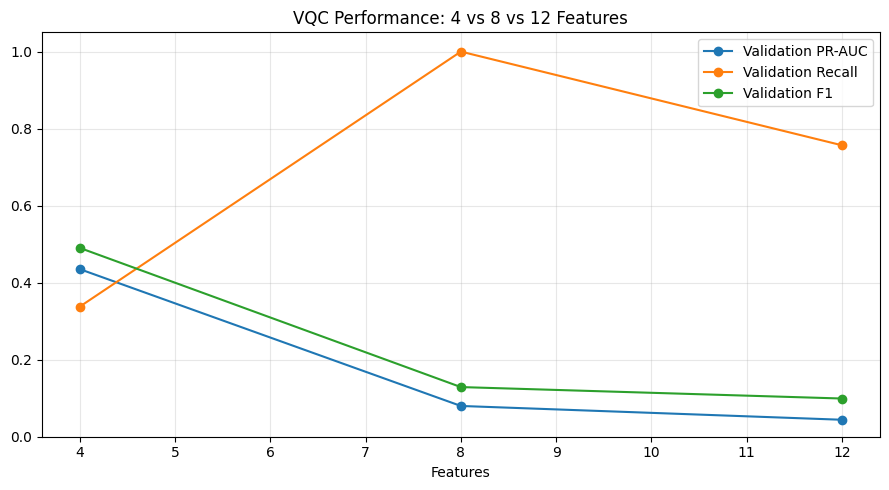

Best validation PR-AUC: 0.4351 with 4 features.


In [9]:

# 7. Faster VQC experiments: 4, 8 and 12 features only

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score
)
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RealAmplitudes
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA
# Start small; increase only after checking the results.
QML_MAXITER = 10
MAX_SAMPLES_PER_CLASS = 500
FEATURE_COUNTS = [4, 8, 12]

# Use a reproducible, class-balanced sample from TRAINING DATA ONLY.
# Validation data is not resampled.
sample_parts = []

for class_label, group in quantum_train.groupby("Class"):
    sample_parts.append(
        group.sample(
            n=min(MAX_SAMPLES_PER_CLASS, len(group)),
            random_state=42
        )
    )

quantum_train_qml = (
    pd.concat(sample_parts)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("Quantum training sample:", quantum_train_qml.shape)
print("Training class counts:")
print(quantum_train_qml["Class"].value_counts())

# Prepare result containers
quantum_models = {}
quantum_scalers = {}
quantum_validation_probabilities = {}
quantum_thresholds = {}
quantum_results = {}
quantum_errors = {}
quantum_experiment_rows = []

y_q_train_small = quantum_train_qml["Class"].to_numpy(dtype=int)
y_q_val_array = np.asarray(y_q_val).astype(int).ravel()


def make_angle_feature_map(n_features):
    params = ParameterVector("x", n_features)
    circuit = QuantumCircuit(n_features)

    for i, param in enumerate(params):
        circuit.ry(param, i)

    return circuit, params


for n_features in FEATURE_COUNTS:
    experiment_name = f"Hybrid VQC - Angle - {n_features} features"

    try:
        # Keep the feature sets already defined in your notebook.
        feature_names = quantum_feature_sets[n_features]

        # Fit preprocessing on the QML training sample only.
        scaler = StandardScaler()
        X_q_train = scaler.fit_transform(
            quantum_train_qml[feature_names]
        )
        X_q_val = scaler.transform(
            X_q_val_raw[feature_names]
        )

        # Bound rotation angles for numerical stability.
        X_q_train = np.clip(X_q_train, -3, 3) * (np.pi / 3)
        X_q_val = np.clip(X_q_val, -3, 3) * (np.pi / 3)

        feature_map, _ = make_angle_feature_map(n_features)
        ansatz = RealAmplitudes(
            n_features, reps=1, entanglement="linear"
        )

        vqc = VQC(
            feature_map=feature_map,
            ansatz=ansatz,
            optimizer=COBYLA(maxiter=QML_MAXITER)
        )

        start_time = time.perf_counter()
        vqc.fit(X_q_train, y_q_train_small)
        train_seconds = time.perf_counter() - start_time

        # Validation probabilities; validation set remains untouched.
        val_output = np.asarray(vqc.predict_proba(X_q_val))
        val_probabilities = (
            val_output[:, 1]
            if val_output.ndim == 2 and val_output.shape[1] > 1
            else val_output.reshape(-1)
        )

        # Select the F1 threshold on validation data only.
        threshold_table = []

        for threshold in thresholds:
            predictions = (val_probabilities >= threshold).astype(int)

            threshold_table.append({
                "Threshold": threshold,
                "Precision": precision_score(
                    y_q_val_array, predictions, zero_division=0
                ),
                "Recall": recall_score(
                    y_q_val_array, predictions, zero_division=0
                ),
                "F1": f1_score(
                    y_q_val_array, predictions, zero_division=0
                )
            })

        threshold_df = pd.DataFrame(threshold_table)
        best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
        best_threshold = float(best_row["Threshold"])

        # PR-AUC and ROC-AUC are calculated from probabilities.
        pr_auc = average_precision_score(
            y_q_val_array, val_probabilities
        )

        try:
            roc_auc = roc_auc_score(
                y_q_val_array, val_probabilities
            )
        except ValueError:
            roc_auc = np.nan

        best_predictions = (
            val_probabilities >= best_threshold
        ).astype(int)

        precision = precision_score(
            y_q_val_array, best_predictions, zero_division=0
        )
        recall = recall_score(
            y_q_val_array, best_predictions, zero_division=0
        )
        f1 = f1_score(
            y_q_val_array, best_predictions, zero_division=0
        )

        quantum_models[n_features] = vqc
        quantum_scalers[n_features] = scaler
        quantum_validation_probabilities[n_features] = val_probabilities
        quantum_thresholds[n_features] = best_threshold

        quantum_results[experiment_name] = {
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "PR-AUC": pr_auc,
            "ROC-AUC": roc_auc,
            "Encoding": "Angle",
            "Qubits": n_features,
            "Circuit Depth": ansatz.depth(),
            "Model Type": "VQC",
            "Training Seconds": train_seconds,
            "Selected Threshold": best_threshold
        }

        quantum_experiment_rows.append({
            "Features": n_features,
            "Qubits": n_features,
            "Validation Precision": precision,
            "Validation Recall": recall,
            "Validation F1": f1,
            "Validation PR-AUC": pr_auc,
            "Validation ROC-AUC": roc_auc,
            "Selected Threshold": best_threshold,
            "Training Seconds": train_seconds,
            "Circuit Depth": ansatz.depth()
        })

        print(
            f"{experiment_name}: "
            f"{train_seconds:.1f}s | "
            f"PR-AUC={pr_auc:.4f} | "
            f"F1={f1:.4f}"
        )

    except Exception as error:
        quantum_errors[experiment_name] = repr(error)
        print(f"{experiment_name} failed: {error}")


# Display and plot completed experiments
if quantum_experiment_rows:
    quantum_feature_comparison = pd.DataFrame(
        quantum_experiment_rows
    ).sort_values("Features")

    display(quantum_feature_comparison.round(4))

    quantum_feature_comparison.plot(
        x="Features",
        y=[
            "Validation PR-AUC",
            "Validation Recall",
            "Validation F1"
        ],
        marker="o",
        figsize=(9, 5),
        title="VQC Performance: 4 vs 8 vs 12 Features"
    )
    plt.ylim(0, 1.05)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    best_row = quantum_feature_comparison.loc[
        quantum_feature_comparison["Validation PR-AUC"].idxmax()
    ]

    best_quantum_feature_count = int(best_row["Features"])
    print(
        f"Best validation PR-AUC: {best_row['Validation PR-AUC']:.4f}"
        f" with {best_quantum_feature_count} features."
    )
else:
    print("No VQC experiment completed successfully.")

if quantum_errors:
    print("\nExperiment errors:")
    for name, error in quantum_errors.items():
        print(name, ":", error)

In [10]:
# 8. Optional PCA experiment (disabled by default because QML simulation is expensive)
RUN_PCA_EXPERIMENT = True
pca_experiment_results = []
if RUN_PCA_EXPERIMENT and QML_AVAILABLE:
    from sklearn.decomposition import PCA
    pca_scaler = StandardScaler()
    X_train_scaled = pca_scaler.fit_transform(X_train)
    X_val_scaled = pca_scaler.transform(X_val)
    for n_components in [4, 8, 12]:
        try:
            pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
            X_train_pca = pca.fit_transform(X_train_scaled)
            X_val_pca = pca.transform(X_val_scaled)
            # Use a small, balanced training sample drawn only from training data.
            train_pca = pd.DataFrame(X_train_pca, index=X_train.index)
            train_pca['Class'] = y_train
            fraud_pca = train_pca[train_pca['Class'] == 1]
            legit_pca = train_pca[train_pca['Class'] == 0].sample(
                n=min(250, int((y_train == 0).sum())), random_state=RANDOM_STATE
            )
            balanced_pca = pd.concat([fraud_pca, legit_pca]).sample(frac=1, random_state=RANDOM_STATE)
            X_pca_train = np.clip(balanced_pca.drop(columns='Class').to_numpy(), -3, 3) * (np.pi / 3)
            y_pca_train = balanced_pca['Class'].to_numpy(dtype=int)
            # Validation is a controlled subset, same rows as other QML experiments.
            X_pca_val = np.clip(X_val_pca[:len(y_q_val)], -3, 3) * (np.pi / 3)
            # Use the actual validation subset indices for PCA, not the first rows of X_val.
            X_pca_val = np.clip(pca.transform(pca_scaler.transform(X_q_val_raw)), -3, 3) * (np.pi / 3)
            pca_map, _ = make_angle_feature_map(n_components)
            pca_ansatz = RealAmplitudes(n_components, reps=1, entanglement='linear')
            pca_vqc = VQC(feature_map=pca_map, ansatz=pca_ansatz, optimizer=COBYLA(maxiter=QML_MAXITER))
            pca_vqc.fit(X_pca_train, y_pca_train)
            pca_prob = pca_vqc.predict_proba(X_pca_val)[:, 1]
            pca_experiment_results.append({
                'Components': n_components,
                'Explained Variance': pca.explained_variance_ratio_.sum(),
                'Validation PR-AUC (controlled subset)': average_precision_score(y_q_val, pca_prob),
                'Validation ROC-AUC (controlled subset)': roc_auc_score(y_q_val, pca_prob),
            })
        except Exception as error:
            print(f'PCA-QML experiment with {n_components} components failed: {error}')
    if pca_experiment_results:
        display(pd.DataFrame(pca_experiment_results).sort_values('Validation PR-AUC (controlled subset)', ascending=False))
else:
    print('Optional PCA-QML experiment is disabled. Set RUN_PCA_EXPERIMENT = True to run it.')

,Components,Explained Variance,Validation PR-AUC (controlled subset),Validation ROC-AUC (controlled subset)
0,4,0.190146,0.094257,0.482784
1,8,0.325109,0.090287,0.458054
2,12,0.459187,0.078548,0.455405


Shared comparison test subset: 1,074 rows; fraud=74; legitimate=1,000
Final shared-subset test comparison (same rows for every model):


,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.9833,0.7973,0.8806,0.9773,0.9185
Logistic Regression,0.9545,0.8514,0.9000,0.9621,0.8920
Logistic Regression + SMOTE,0.9836,0.8108,0.8889,0.9591,0.8856
Random Forest,1.0000,0.8243,0.9037,0.9369,0.8856
"Neural Network (1 hidden layer, scikit-learn/CPU)",0.9833,0.7973,0.8806,0.9601,0.8806
"Neural Network (2 hidden layers, scikit-learn/CPU)",0.9655,0.7568,0.8485,0.9607,0.8765
PyTorch MLP (GPU when available),0.9818,0.7297,0.8372,0.8924,0.8294
Hybrid VQC - Angle - 4 features,0.8378,0.4189,0.5586,0.7063,0.5199
Hybrid VQC - Angle - 8 features,0.0689,1.0000,0.1289,0.2187,0.1275
Hybrid VQC - Angle - 12 features,0.0558,0.7973,0.1042,0.1028,0.0420


Classical and neural models on the complete untouched test set (natural prevalence):


,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest,0.8356,0.8243,0.8299,0.9372,0.8147
XGBoost,0.7867,0.7973,0.7919,0.9777,0.8140
"Neural Network (2 hidden layers, scikit-learn/CPU)",0.7273,0.7568,0.7417,0.9642,0.7110
PyTorch MLP (GPU when available),0.8571,0.7297,0.7883,0.8948,0.7088
Logistic Regression + SMOTE,0.6742,0.8108,0.7362,0.9601,0.7072
"Neural Network (1 hidden layer, scikit-learn/CPU)",0.8194,0.7973,0.8082,0.9624,0.7072
Logistic Regression,0.3500,0.8514,0.4961,0.9626,0.6694


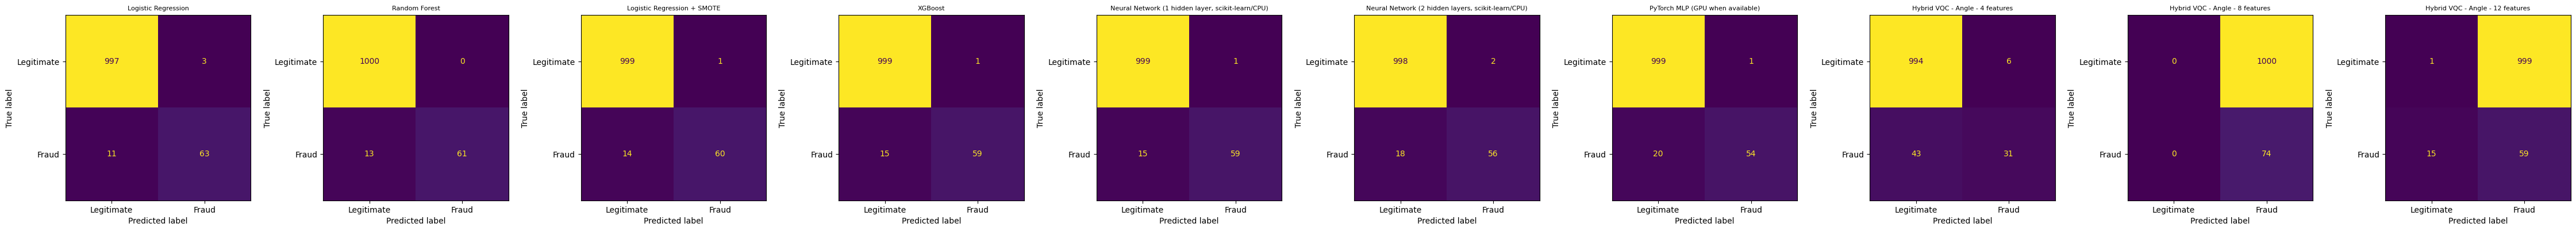

In [11]:
# 9. Final comparison on one shared, untouched test subset
# To keep QML inference tractable, the primary shared comparison uses every fraud test case
# plus a reproducible sample of legitimate cases. ALL models below are evaluated on these same rows.
# Because this is a fraud-enriched case-control subset, its precision/PR-AUC do not represent
# natural deployment prevalence. A separate full-test classical report follows.
FINAL_TEST_LEGITIMATE_LIMIT = 1000
if len(X_test) > FINAL_TEST_LEGITIMATE_LIMIT:
    test_source = X_test.copy()
    test_source['Class'] = y_test
    fraud_test_rows = test_source[test_source['Class'] == 1]
    legit_test_rows = test_source[test_source['Class'] == 0].sample(
        n=min(FINAL_TEST_LEGITIMATE_LIMIT, int((y_test == 0).sum())), random_state=RANDOM_STATE
    )
    shared_test = pd.concat([fraud_test_rows, legit_test_rows]).sample(frac=1, random_state=RANDOM_STATE)
else:
    shared_test = X_test.copy()
    shared_test['Class'] = y_test
X_shared_test = shared_test.drop(columns='Class')
y_shared_test = shared_test['Class'].to_numpy(dtype=int)
print(f'Shared comparison test subset: {len(shared_test):,} rows; fraud={int(y_shared_test.sum()):,}; legitimate={int((y_shared_test == 0).sum()):,}')

final_test_results = {}
final_test_probabilities = {}
final_test_thresholds = {}
for name, model in models.items():
    probs = model.predict_proba(X_shared_test)[:, 1]
    threshold = thresholds_by_model.get(name, 0.5)
    final_test_probabilities[name] = probs
    final_test_thresholds[name] = threshold
    final_test_results[name] = evaluate_probabilities(y_shared_test, probs, threshold)

X_nn_shared_test = nn_preprocessor.transform(X_shared_test)
for name, model in neural_models.items():
    probs = model.predict_proba(X_nn_shared_test)[:, 1]
    threshold = thresholds_by_model.get(name, 0.5)
    final_test_probabilities[name] = probs
    final_test_thresholds[name] = threshold
    final_test_results[name] = evaluate_probabilities(y_shared_test, probs, threshold)

# Add EVERY successfully trained angle-encoding VQC (4, 8 and 12 features)
# to the same shared test subset. Thresholds were selected on validation data only.
if QML_AVAILABLE and quantum_models:
    for n_features, selected_vqc in sorted(quantum_models.items()):
        if n_features not in [4, 8, 12]:
            continue

        feature_names = quantum_feature_sets[n_features]
        scaler = quantum_scalers[n_features]
        X_q_test = scaler.transform(X_shared_test[feature_names])
        X_q_test = np.clip(X_q_test, -3, 3) * (np.pi / 3)

        q_probs_raw = np.asarray(selected_vqc.predict_proba(X_q_test))
        q_probs = (
            q_probs_raw[:, 1]
            if q_probs_raw.ndim == 2 and q_probs_raw.shape[1] > 1
            else q_probs_raw.reshape(-1)
        )

        q_name = f'Hybrid VQC - Angle - {n_features} features'
        q_threshold = quantum_thresholds[n_features]
        final_test_probabilities[q_name] = q_probs
        final_test_thresholds[q_name] = q_threshold
        final_test_results[q_name] = evaluate_probabilities(
            y_shared_test, q_probs, q_threshold
        )

final_comparison = pd.DataFrame({
    name: {metric: values[metric] for metric in ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']}
    for name, values in final_test_results.items()
}).T.sort_values('PR-AUC', ascending=False)
print('Final shared-subset test comparison (same rows for every model):')
display(final_comparison.style.format('{:.4f}'))

# Full-test classical baseline metrics on natural test prevalence (do not compare these directly to subset PR-AUC).
full_test_classical = {}
for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]
    full_test_classical[name] = evaluate_probabilities(y_test, probs, thresholds_by_model.get(name, 0.5))
X_nn_test = nn_preprocessor.transform(X_test)
for name, model in neural_models.items():
    probs = model.predict_proba(X_nn_test)[:, 1]
    full_test_classical[name] = evaluate_probabilities(y_test, probs, thresholds_by_model.get(name, 0.5))
full_test_comparison = pd.DataFrame({
    name: {metric: result[metric] for metric in ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']}
    for name, result in full_test_classical.items()
}).T.sort_values('PR-AUC', ascending=False)
print('Classical and neural models on the complete untouched test set (natural prevalence):')
display(full_test_comparison.style.format('{:.4f}'))

# Confusion matrices for shared-subset results.
n_models = len(final_test_results)
fig, axes = plt.subplots(1, n_models, figsize=(4.5 * n_models, 4))
if n_models == 1:
    axes = [axes]
for axis, (name, values) in zip(axes, final_test_results.items()):
    ConfusionMatrixDisplay(values['Confusion Matrix'], display_labels=['Legitimate', 'Fraud']).plot(ax=axis, colorbar=False)
    axis.set_title(name, fontsize=8)
plt.tight_layout(); plt.show()

if quantum_errors:
    print('Quantum experiments that could not run:')
    for name, error in quantum_errors.items():
        print(f'- {name}: {error}')

## Evaluation and reproducibility notes

- Correlation and VIF diagnostics use training data only. VIF is calculated on a reproducible sample to control runtime.
- The split is stratified 70% train / 15% validation / 15% test.
- Scalers, feature ranking, PCA, and oversampling are fitted/applied only using training data.
- Thresholds and quantum feature counts are selected using validation results, never the final test labels.
- The shared quantum comparison test subset contains all fraud cases plus a sample of legitimate cases so inference is computationally feasible. All compared models use exactly the same subset, but its fraud prevalence is enriched; do not interpret its precision/PR-AUC as deployment estimates. The full-test classical report preserves the natural test prevalence.
- `V1`-`V28` are already PCA-transformed features. The optional second PCA experiment is exploratory and disabled by default.
- Qiskit APIs differ by version. If a QML experiment fails, the notebook prints the error while allowing the remaining cells to run where possible. Record package versions and report unavailable methods transparently.